# IBM Data Science Capstone — Notebook 4: Exploratory Data Analysis with SQL

This notebook reproduces the **SQL analysis workflow** using the historical IBM `Spacex.csv` dataset (separate from the 90-row Falcon 9 machine-learning dataset). SQL queries execute on an in-memory SQLite database; results are displayed and exported for the final report.

**Source:** IBM Skills Network, `IBM-DS0321EN-SkillsNetwork/labs/module_2/data/Spacex.csv`.

The figures and tables must be generated by running all cells. No results have been pre-filled.

In [1]:
import pandas as pd
import sqlite3
from pathlib import Path
from IPython.display import display

DATA_URL = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
            "IBM-DS0321EN-SkillsNetwork/labs/module_2/data/Spacex.csv")
OUTPUT = Path("spacex_sql_outputs")
OUTPUT.mkdir(exist_ok=True)

# Download the IBM course dataset; if unavailable, upload Spacex.csv manually.
try:
    df = pd.read_csv(DATA_URL)
    print("Loaded dataset from IBM Skills Network")
except Exception as e:
    print("Direct download unavailable:", e)
    print("Upload the official Spacex.csv file in the Colab dialog.")
    from google.colab import files
    uploaded = files.upload()
    match = next((k for k in uploaded if k.lower().endswith('.csv')), None)
    if match is None:
        raise ValueError("Please upload the official Spacex.csv")
    df = pd.read_csv(match)

# IBM dataset sometimes includes a Byte Order Mark / spaces.
df.columns = df.columns.str.replace("\ufeff", "", regex=False).str.strip()
required = {"Launch_Site", "Orbit", "Mission_Outcome", "Landing_Outcome",
            "PAYLOAD_MASS__KG_", "Booster_Version"}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f"Wrong dataset format; missing columns: {sorted(missing)}. Columns: {df.columns.tolist()}")
print("Dataset dimensions:", df.shape)
display(df.head())
display(df.isna().sum().rename("Null values").to_frame())


Loaded dataset from IBM Skills Network
Dataset dimensions: (101, 10)


,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt


,Null values
Date,0
Time (UTC),0
Booster_Version,0
Launch_Site,0
Payload,0
PAYLOAD_MASS__KG_,0
Orbit,0
Customer,0
Mission_Outcome,0
Landing_Outcome,0


## SQLite setup

The table is named `SPACEXTBL`, as in the IBM assessment. Each query below is executable and its output is saved to CSV.

In [2]:
conn = sqlite3.connect(":memory:")
df.to_sql("SPACEXTBL", conn, index=False, if_exists="replace")

results = {}
def run_sql(name, sql):
    print(f"\n{name}\n{'-'*55}\n{sql.strip()}")
    table = pd.read_sql_query(sql, conn)
    display(table)
    table.to_csv(OUTPUT / f"{name}.csv", index=False)
    results[name] = table
    return table

run_sql("00_preview", "SELECT * FROM SPACEXTBL LIMIT 20;")



00_preview
-------------------------------------------------------
SELECT * FROM SPACEXTBL LIMIT 20;


,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt
5,2013-09-29,16:00:00,F9 v1.1 B1003,VAFB SLC-4E,CASSIOPE,500,Polar LEO,MDA,Success,Uncontrolled (ocean)
6,2013-12-03,22:41:00,F9 v1.1,CCAFS LC-40,SES-8,3170,GTO,SES,Success,No attempt
7,2014-01-06,22:06:00,F9 v1.1,CCAFS LC-40,Thaicom 6,3325,GTO,Thaicom,Success,No attempt
8,2014-04-18,19:25:00,F9 v1.1,CCAFS LC-40,SpaceX CRS-3,2296,LEO (ISS),NASA (CRS),Success,Controlled (ocean)
9,2014-07-14,15:15:00,F9 v1.1,CCAFS LC-40,OG2 Mission 1 6 Orbcomm-OG2 satellites,1316,LEO,Orbcomm,Success,Controlled (ocean)


,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt
5,2013-09-29,16:00:00,F9 v1.1 B1003,VAFB SLC-4E,CASSIOPE,500,Polar LEO,MDA,Success,Uncontrolled (ocean)
6,2013-12-03,22:41:00,F9 v1.1,CCAFS LC-40,SES-8,3170,GTO,SES,Success,No attempt
7,2014-01-06,22:06:00,F9 v1.1,CCAFS LC-40,Thaicom 6,3325,GTO,Thaicom,Success,No attempt
8,2014-04-18,19:25:00,F9 v1.1,CCAFS LC-40,SpaceX CRS-3,2296,LEO (ISS),NASA (CRS),Success,Controlled (ocean)
9,2014-07-14,15:15:00,F9 v1.1,CCAFS LC-40,OG2 Mission 1 6 Orbcomm-OG2 satellites,1316,LEO,Orbcomm,Success,Controlled (ocean)


## Queries and evidence for the report

Keep each resulting table and add a short interpretation to the SQL slides. Counts reflect **this SQL dataset**, not necessarily the separate 90-launch classification dataset.

In [3]:
run_sql("01_unique_launch_sites", """
SELECT DISTINCT Launch_Site
FROM SPACEXTBL
ORDER BY Launch_Site;
""")

run_sql("02_launches_per_site", """
SELECT Launch_Site, COUNT(*) AS Launch_Count
FROM SPACEXTBL
GROUP BY Launch_Site
ORDER BY Launch_Count DESC;
""")

run_sql("03_payload_min_max_avg", """
SELECT MIN(PAYLOAD_MASS__KG_) AS Minimum_Payload_kg,
       MAX(PAYLOAD_MASS__KG_) AS Maximum_Payload_kg,
       ROUND(AVG(PAYLOAD_MASS__KG_), 2) AS Average_Payload_kg
FROM SPACEXTBL;
""")

run_sql("04_total_payload_mass", """
SELECT SUM(PAYLOAD_MASS__KG_) AS Total_Payload_Mass
FROM SPACEXTBL;
""")



01_unique_launch_sites
-------------------------------------------------------
SELECT DISTINCT Launch_Site
FROM SPACEXTBL
ORDER BY Launch_Site;


,Launch_Site
0,CCAFS LC-40
1,CCAFS SLC-40
2,KSC LC-39A
3,VAFB SLC-4E



02_launches_per_site
-------------------------------------------------------
SELECT Launch_Site, COUNT(*) AS Launch_Count
FROM SPACEXTBL
GROUP BY Launch_Site
ORDER BY Launch_Count DESC;


,Launch_Site,Launch_Count
0,CCAFS SLC-40,34
1,CCAFS LC-40,26
2,KSC LC-39A,25
3,VAFB SLC-4E,16



03_payload_min_max_avg
-------------------------------------------------------
SELECT MIN(PAYLOAD_MASS__KG_) AS Minimum_Payload_kg,
       MAX(PAYLOAD_MASS__KG_) AS Maximum_Payload_kg,
       ROUND(AVG(PAYLOAD_MASS__KG_), 2) AS Average_Payload_kg
FROM SPACEXTBL;


,Minimum_Payload_kg,Maximum_Payload_kg,Average_Payload_kg
0,0,15600,6138.29



04_total_payload_mass
-------------------------------------------------------
SELECT SUM(PAYLOAD_MASS__KG_) AS Total_Payload_Mass
FROM SPACEXTBL;


,Total_Payload_Mass
0,619967


,Total_Payload_Mass
0,619967


In [4]:
run_sql("05_mission_outcome_by_site", """
SELECT Launch_Site, Mission_Outcome, COUNT(*) AS Mission_Outcome_Count
FROM SPACEXTBL
GROUP BY Launch_Site, Mission_Outcome
ORDER BY Launch_Site, Mission_Outcome_Count DESC;
""")

run_sql("06_landing_outcomes", """
SELECT Landing_Outcome, COUNT(*) AS Landing_Count
FROM SPACEXTBL
GROUP BY Landing_Outcome
ORDER BY Landing_Count DESC;
""")

run_sql("07_successful_drone_ship_landings", """
SELECT COUNT(*) AS Successful_ASDS_Landings
FROM SPACEXTBL
WHERE Landing_Outcome = 'Success (drone ship)';
""")

run_sql("08_orbit_counts", """
SELECT Orbit, COUNT(*) AS Launch_Count
FROM SPACEXTBL
GROUP BY Orbit
ORDER BY Launch_Count DESC;
""")

run_sql("09_geosynchronous_orbit", """
SELECT COUNT(*) AS GEO_Count
FROM SPACEXTBL
WHERE Orbit = 'GEO';
""")

run_sql("10_geostationary_transfer_orbit", """
SELECT COUNT(*) AS GTO_Count
FROM SPACEXTBL
WHERE Orbit = 'GTO';
""")



05_mission_outcome_by_site
-------------------------------------------------------
SELECT Launch_Site, Mission_Outcome, COUNT(*) AS Mission_Outcome_Count
FROM SPACEXTBL
GROUP BY Launch_Site, Mission_Outcome
ORDER BY Launch_Site, Mission_Outcome_Count DESC;


,Launch_Site,Mission_Outcome,Mission_Outcome_Count
0,CCAFS LC-40,Success,25
1,CCAFS LC-40,Failure (in flight),1
2,CCAFS SLC-40,Success,32
3,CCAFS SLC-40,Success (payload status unclear),1
4,CCAFS SLC-40,Success,1
5,KSC LC-39A,Success,25
6,VAFB SLC-4E,Success,16



06_landing_outcomes
-------------------------------------------------------
SELECT Landing_Outcome, COUNT(*) AS Landing_Count
FROM SPACEXTBL
GROUP BY Landing_Outcome
ORDER BY Landing_Count DESC;


,Landing_Outcome,Landing_Count
0,Success,38
1,No attempt,21
2,Success (drone ship),14
3,Success (ground pad),9
4,Failure (drone ship),5
5,Controlled (ocean),5
6,Failure,3
7,Uncontrolled (ocean),2
8,Failure (parachute),2
9,Precluded (drone ship),1



07_successful_drone_ship_landings
-------------------------------------------------------
SELECT COUNT(*) AS Successful_ASDS_Landings
FROM SPACEXTBL
WHERE Landing_Outcome = 'Success (drone ship)';


...


09_geosynchronous_orbit
-------------------------------------------------------
SELECT COUNT(*) AS GEO_Count
FROM SPACEXTBL
WHERE Orbit = 'GEO';


,GEO_Count
0,0



10_geostationary_transfer_orbit
-------------------------------------------------------
SELECT COUNT(*) AS GTO_Count
FROM SPACEXTBL
WHERE Orbit = 'GTO';


,GTO_Count
0,30


,GTO_Count
0,30


## Visualization from SQL results

The following chart is derived directly from the `COUNT(*) GROUP BY Launch_Site` query, not an illustrative mock-up.

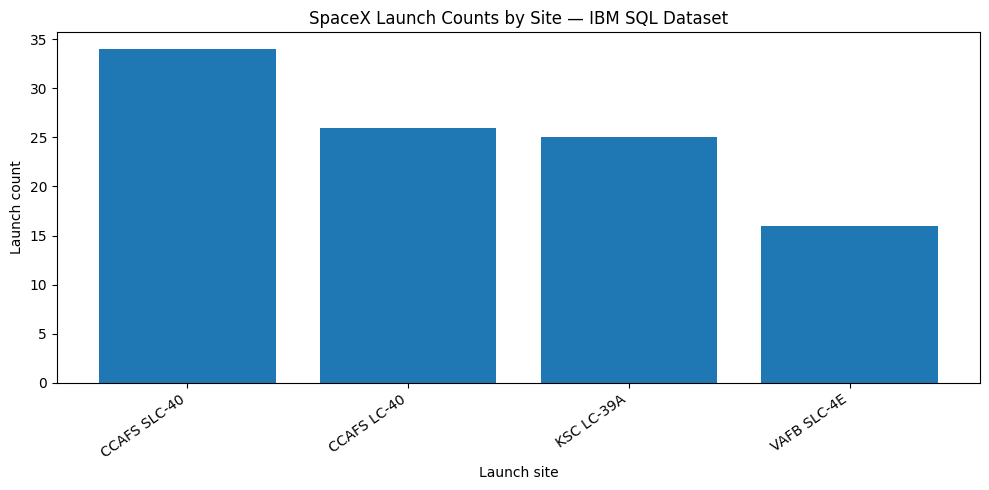

In [5]:
import matplotlib.pyplot as plt
site = results["02_launches_per_site"]
plt.figure(figsize=(10, 5))
plt.bar(site["Launch_Site"], site["Launch_Count"])
plt.xlabel("Launch site")
plt.ylabel("Launch count")
plt.title("SpaceX Launch Counts by Site — IBM SQL Dataset")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT / "sql_launches_by_site.png", dpi=180)
plt.show()


## Consistency checks and report notes

- `GEO` and `GTO` are different orbit labels. Do not interpret them as the same value.
- `Mission_Outcome` is **not** the same as `Landing_Outcome`.
- `Landing_Outcome = 'Success (drone ship)'` is specific to this IBM SQL dataset; the classification dataset uses labels such as `True ASDS`.
- The historical dataset might not reflect launches that occurred after the course snapshot.

In [6]:
print("Rows in SQL source:", len(df))
print("Exported result tables:", len(results))
print("Files saved to:", OUTPUT.resolve())
print("SQL EDA notebook completed.")

# Download one archive containing all tables and chart, convenient for GitHub.
import shutil
archive = shutil.make_archive("spacex_sql_outputs", "zip", OUTPUT)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Archive:", archive)


Rows in SQL source: 101
Exported result tables: 11
Files saved to: /content/spacex_sql_outputs
SQL EDA notebook completed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>